<a href="https://colab.research.google.com/github/RachmadAprisandhy/PembelajaranMesin/blob/main/JS07/JS07_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

import data terlebih dahulu

In [2]:
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
path = '/content/drive/MyDrive/Pembelajaran mesin/CC_Customer_Dataset.csv'
data = pd.read_csv(path)

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors

In [8]:
display(data.head())
print(data.columns.tolist())
print("Ukuran dataset:", data.shape)

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Ukuran dataset: (660, 7)


1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Apakah sebaran data dapat dikatakan linier?

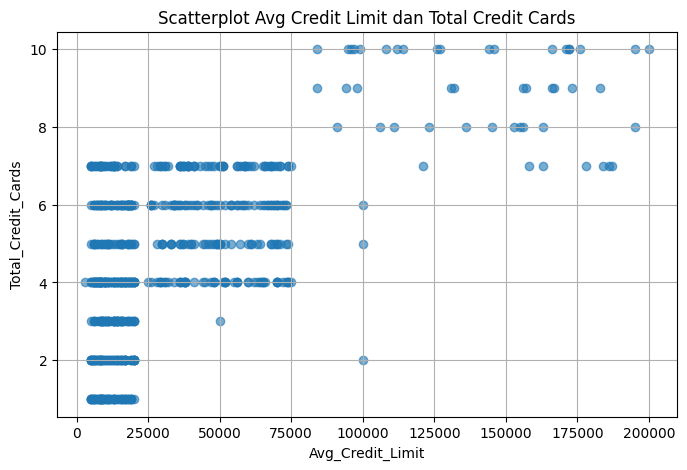

In [10]:
# Sesuaikan nama kolom jumlah kartu dengan header pada CSV
if "Total_Credit_Cards" in data.columns:
    kolom_kartu = "Total_Credit_Cards"
elif "Total_Credit_Card" in data.columns:
    kolom_kartu = "Total_Credit_Card"
else:
    raise KeyError("Kolom jumlah kartu tidak ditemukan. Periksa nama kolom dengan df.columns.tolist().")

kolom_limit = "Avg_Credit_Limit"

# Ambil dua kolom dan buang baris yang kosong
data_scatter = data[[kolom_limit, kolom_kartu]].dropna()

# Buat scatterplot
plt.figure(figsize=(8, 5))
plt.scatter(
    data_scatter[kolom_limit],
    data_scatter[kolom_kartu],
    alpha=0.6
)
plt.xlabel("Avg_Credit_Limit")
plt.ylabel(kolom_kartu)
plt.title("Scatterplot Avg Credit Limit dan Total Credit Cards")
plt.grid(True)
plt.show()

cek korelasi dan hubungan linear

In [11]:
korelasi = data_scatter[kolom_limit].corr(data_scatter[kolom_kartu])
print("Korelasi Pearson:", korelasi)

Korelasi Pearson: 0.6088604935524963


2.
Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah
k
k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

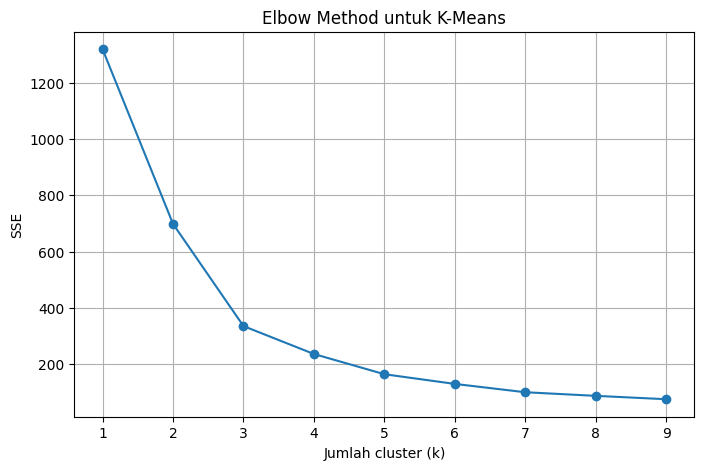

In [12]:
X_kmeans = data_scatter[[kolom_limit, kolom_kartu]]

scaler_kmeans = StandardScaler()
X_kmeans_scaled = scaler_kmeans.fit_transform(X_kmeans)

daftar_k = range(1, 10)
daftar_sse = []

for k in daftar_k:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_kmeans_scaled)
    daftar_sse.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(daftar_k, daftar_sse, marker="o")
plt.xticks(list(daftar_k))
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("SSE")
plt.title("Elbow Method untuk K-Means")
plt.grid(True)
plt.show()

3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.

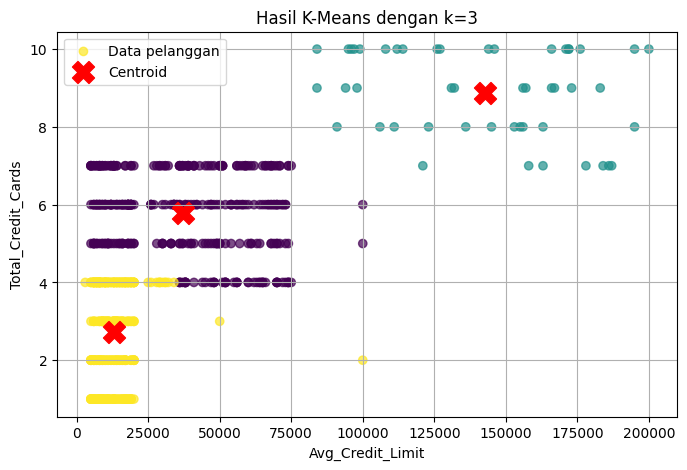

In [13]:
best_k = 3

model_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)
label_kmeans = model_kmeans.fit_predict(X_kmeans_scaled)

centroid = scaler_kmeans.inverse_transform(model_kmeans.cluster_centers_)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_kmeans[kolom_limit],
    X_kmeans[kolom_kartu],
    c=label_kmeans,
    cmap="viridis",
    alpha=0.7,
    label="Data pelanggan"
)
plt.scatter(
    centroid[:, 0],
    centroid[:, 1],
    color="red",
    marker="X",
    s=250,
    label="Centroid"
)
plt.xlabel("Avg_Credit_Limit")
plt.ylabel(kolom_kartu)
plt.title(f"Hasil K-Means dengan k={best_k}")
plt.legend()
plt.grid(True)
plt.show()

4. Buatlah model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.

In [15]:
# Ambil semua kolom numerik
data_numerik = data.select_dtypes(include="number").copy()

# Buang kolom ID jika ada
kolom_id = [
    kolom for kolom in data_numerik.columns
    if kolom.lower().replace("_", " ").strip()
    in ["sl no", "customer key", "id", "index"]
]

X_dbscan = data_numerik.drop(columns=kolom_id)

X_dbscan = X_dbscan.dropna()

print("Fitur yang dipakai DBSCAN:", X_dbscan.columns.tolist())
print("Kolom ID yang dikeluarkan:", kolom_id)

scaler_dbscan = StandardScaler()
X_dbscan_scaled = scaler_dbscan.fit_transform(X_dbscan)

Fitur yang dipakai DBSCAN: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Kolom ID yang dikeluarkan: ['Sl_No', 'Customer Key']


5. Tentukan jumlah
k
k yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

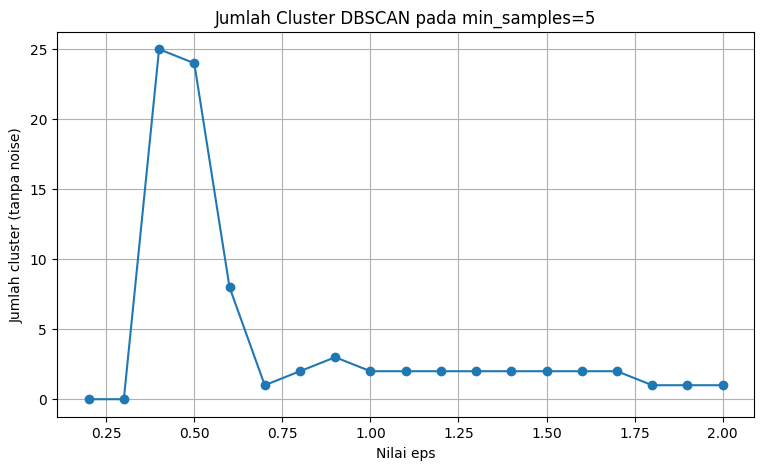

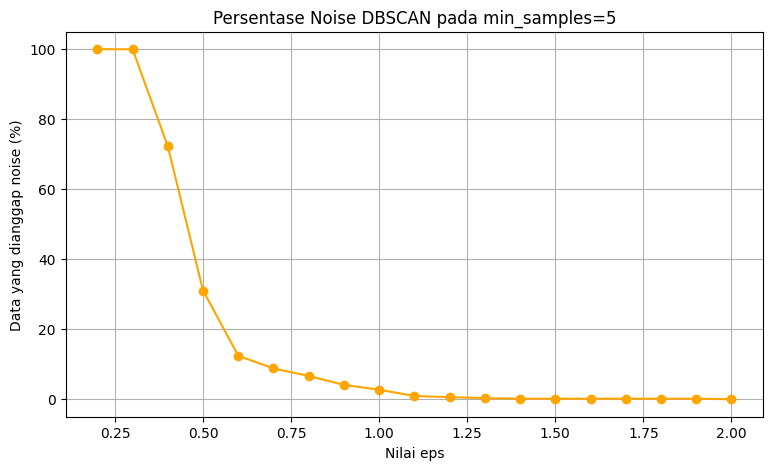

In [16]:
daftar_eps = np.arange(0.2, 2.1, 0.1)
min_samples = 5

jumlah_cluster = []
persen_noise = []

for eps in daftar_eps:
    model = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )
    label = model.fit_predict(X_dbscan_scaled)

    # Label -1 menandakan noise
    cluster_terbentuk = set(label) - {-1}
    jumlah_cluster.append(len(cluster_terbentuk))
    persen_noise.append(np.mean(label == -1) * 100)

# Linechart jumlah cluster dan noise
plt.figure(figsize=(9, 5))
plt.plot(daftar_eps, jumlah_cluster, marker="o")
plt.xlabel("Nilai eps")
plt.ylabel("Jumlah cluster (tanpa noise)")
plt.title(f"Jumlah Cluster DBSCAN pada min_samples={min_samples}")
plt.grid(True)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(daftar_eps, persen_noise, marker="o", color="orange")
plt.xlabel("Nilai eps")
plt.ylabel("Data yang dianggap noise (%)")
plt.title(f"Persentase Noise DBSCAN pada min_samples={min_samples}")
plt.grid(True)
plt.show()

In [17]:
eps_pilihan = 0.5
min_samples_pilihan = 5

model_dbscan = DBSCAN(
    eps=eps_pilihan,
    min_samples=min_samples_pilihan
)
label_dbscan = model_dbscan.fit_predict(X_dbscan_scaled)

print("Label cluster DBSCAN:", np.unique(label_dbscan))
print("Jumlah cluster tanpa noise:", len(set(label_dbscan) - {-1}))
print("Jumlah data noise:", np.sum(label_dbscan == -1))

Label cluster DBSCAN: [-1  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22
 23]
Jumlah cluster tanpa noise: 24
Jumlah data noise: 205


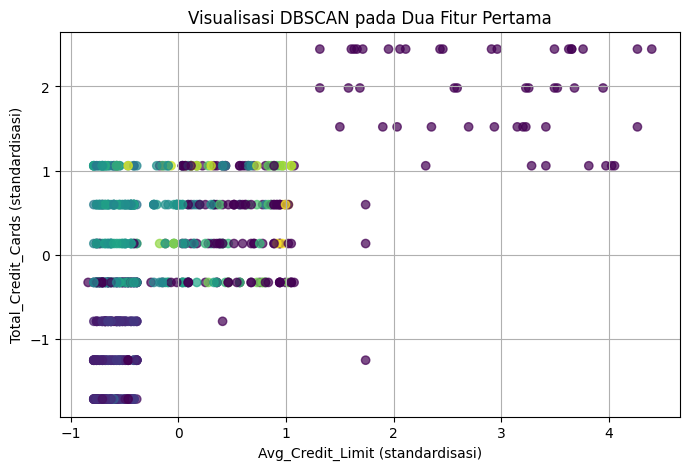

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X_dbscan_scaled[:, 0],
    X_dbscan_scaled[:, 1],
    c=label_dbscan,
    cmap="viridis",
    alpha=0.7
)
plt.xlabel(X_dbscan.columns[0] + " (standardisasi)")
plt.ylabel(X_dbscan.columns[1] + " (standardisasi)")
plt.title("Visualisasi DBSCAN pada Dua Fitur Pertama")
plt.grid(True)
plt.show()

6. Tentukan nilai silhouette score dan DBI dari model DBSCAN.

In [19]:
mask_non_noise = label_dbscan != -1
label_non_noise = label_dbscan[mask_non_noise]
data_non_noise = X_dbscan_scaled[mask_non_noise]

jumlah_cluster_non_noise = len(set(label_non_noise))

if jumlah_cluster_non_noise >= 2:
    nilai_silhouette = silhouette_score(
        data_non_noise,
        label_non_noise
    )
    nilai_dbi = davies_bouldin_score(
        data_non_noise,
        label_non_noise
    )

    print("Silhouette Score:", nilai_silhouette)
    print("Davies-Bouldin Index:", nilai_dbi)
    print("Persentase noise:", np.mean(label_dbscan == -1) * 100, "%")
else:
    print(
        "Metrik belum dapat dihitung karena hasil DBSCAN "
        "memiliki kurang dari dua cluster non-noise."
    )
    print("Coba sesuaikan eps atau min_samples berdasarkan grafik nomor 5.")

Silhouette Score: 0.026998919881489288
Davies-Bouldin Index: 1.4334915083887771
Persentase noise: 31.060606060606062 %
